**Notebook 03: Practice-level dataset**

This notebook builds the practice-level dataset used in the regression (notebook 04). For each GP practice in the three West Midlands ICBs it joins the generic dapagliflozin share from September 2025, deprivation (IMD 2019), diabetes prevalence and list size.

Inputs: the three OpenPrescribing practice files, the QOF 2024/25 files, `GP_Practice_Postcode_Lookup.csv`, `IMD_2019.csv` and `postcode_lsoa_lookup.csv` (made in notebook 03a).

Outputs: `practice_master_lookup.csv` (one row per practice, also used by notebook 05) and `practice_level_regression_data.csv`. Each run replaces the old versions.

**Step 1: Load libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded')

Libraries loaded


**Step 2: Get the practice list from the QOF mapping file**

Practices are chosen by their ICB code, not by the first letters of the practice code. The three ICB codes are QHL (Birmingham and Solihull), QUA (Black Country) and QWU (Coventry and Warwickshire). Practice codes starting with M84 and M86 belong to Coventry and Warwickshire, so a prefix filter would have missed them.

In [2]:
ICBS = {'QHL': 'Birmingham and Solihull',
        'QUA': 'Black Country',
        'QWU': 'Coventry and Warwickshire'}

geo = pd.read_csv('QOF_2024_25/MAPPING_NHS_GEOGRAPHIES_2425.csv')
master = geo[geo['ICB_ODS_CODE'].isin(ICBS)][
    ['PRACTICE_CODE', 'PRACTICE_NAME', 'ICB_ODS_CODE', 'SUB_ICB_ODS_CODE']].copy()
master['icb'] = master['ICB_ODS_CODE'].map(ICBS)

print('Practices in the three ICBs:', master.shape[0])
print(master.groupby('icb').size())

Practices in the three ICBs: 465
icb
Birmingham and Solihull      175
Black Country                171
Coventry and Warwickshire    119
dtype: int64


**Step 3: Add practice postcodes**

The NHS practice file (epraccur) has no header row, so it is read with `header=None`. Column 0 is the practice code and column 9 is the postcode.

In [3]:
gp = pd.read_csv('GP_Practice_Postcode_Lookup.csv', header=None)[[0, 9]]
gp.columns = ['PRACTICE_CODE', 'postcode']
gp['postcode'] = gp['postcode'].str.strip().str.upper()

master = master.merge(gp, on='PRACTICE_CODE', how='left')
print('Practices without a postcode:', master['postcode'].isnull().sum())

Practices without a postcode: 0


**Step 4: Add LSOA and district from the postcode**

`postcode_lsoa_lookup.csv` (from notebook 03a) gives the 2011 LSOA code and the local authority district for each postcode. The 2011 LSOA code is used because IMD 2019 is built on 2011 boundaries.

In [4]:
pc = pd.read_csv('postcode_lsoa_lookup.csv').rename(columns={'admin_district': 'district'})
master = master.merge(pc, on='postcode', how='left')

print('Practices without an LSOA:', master['lsoa11'].isnull().sum())
print(master.groupby(['icb', 'district']).size())

Practices without an LSOA: 0
icb                        district             
Birmingham and Solihull    Birmingham               155
                           Solihull                  19
                           Walsall                    1
Black Country              Birmingham                 1
                           Dudley                    44
                           Sandwell                  45
                           Walsall                   50
                           Wolverhampton             31
Coventry and Warwickshire  Coventry                  50
                           North Warwickshire         8
                           Nuneaton and Bedworth     17
                           Rugby                     12
                           Stratford-on-Avon         17
                           Warwick                   15
dtype: int64


**Step 5: Add deprivation (IMD 2019)**

Two versions are added. `imd_practice` is the IMD score of the LSOA where the surgery is located. It differs for each practice, but it describes the surgery's location and not where its patients live. `imd_district` is the average score for the whole district, as described in the proposal. It has only 12 distinct values, so it behaves like a district effect.

In [5]:
imd = pd.read_csv('ONS_data/IMD_2019.csv').rename(columns={
    'LSOA code (2011)': 'lsoa11',
    'Local Authority District name (2019)': 'lad',
    'Index of Multiple Deprivation (IMD) Score': 'imd_score',
    'Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)': 'imd_decile'})

# Practice level: IMD of the surgery's LSOA
master = master.merge(
    imd[['lsoa11', 'imd_score', 'imd_decile']].rename(
        columns={'imd_score': 'imd_practice', 'imd_decile': 'imd_decile_practice'}),
    on='lsoa11', how='left')

# District level: average IMD over all LSOAs in the district
district_imd = imd.groupby('lad').agg(
    imd_district=('imd_score', 'mean'),
    imd_decile_district=('imd_decile', 'mean')
).reset_index().rename(columns={'lad': 'district'})
master = master.merge(district_imd, on='district', how='left')

print('Practices without practice-level IMD:', master['imd_practice'].isnull().sum())
print('Practices without district IMD:', master['imd_district'].isnull().sum())
print(district_imd[district_imd['district'].isin(master['district'])].round(1).to_string(index=False))

Practices without practice-level IMD: 0
Practices without district IMD: 0
             district  imd_district  imd_decile_district
           Birmingham          37.6                  2.9
             Coventry          25.4                  4.7
               Dudley          23.3                  5.1
   North Warwickshire          18.0                  5.8
Nuneaton and Bedworth          22.9                  5.0
                Rugby          13.9                  6.9
             Sandwell          34.9                  2.8
             Solihull          17.8                  6.6
    Stratford-on-Avon          11.7                  7.4
              Walsall          30.7                  3.8
              Warwick          12.1                  7.5
        Wolverhampton          31.5                  3.5


**Step 6: Add diabetes prevalence and list size (QOF 2024/25)**

Prevalence is the diabetes register divided by the practice list size, using the list for patients aged 17 and over (`17OV`).

In [6]:
qof = pd.read_csv('QOF_2024_25/PREVALENCE_2425.csv')
dm = qof[(qof['GROUP_CODE'] == 'DM') & (qof['PATIENT_LIST_TYPE'] == '17OV')][
    ['PRACTICE_CODE', 'REGISTER', 'PRACTICE_LIST_SIZE']].rename(
    columns={'REGISTER': 'dm_register', 'PRACTICE_LIST_SIZE': 'list_size'})
dm['diabetes_prevalence'] = dm['dm_register'] / dm['list_size']

master = master.merge(dm, on='PRACTICE_CODE', how='left')
print('Practices without diabetes data:', master['diabetes_prevalence'].isnull().sum())
print(master['diabetes_prevalence'].describe().round(4))

Practices without diabetes data: 0
count    465.0000
mean       0.0958
std        0.0252
min        0.0142
25%        0.0816
50%        0.0957
75%        0.1088
max        0.1765
Name: diabetes_prevalence, dtype: float64


**Step 7: Save the master practice lookup**

This file has one row per practice with its ICB, district, IMD, prevalence and list size. Notebook 05 uses it to pick the right practices from the prescribing data.

In [7]:
print('Missing values in the master lookup:', master.isnull().sum().sum())
master.to_csv('practice_master_lookup.csv', index=False)
print('Saved practice_master_lookup.csv:', master.shape)

Missing values in the master lookup: 0
Saved practice_master_lookup.csv: (465, 15)


**Step 8: Load the OpenPrescribing practice files and keep the study window**

Each file holds one sub-ICB and runs to July 2026, so rows are cut to January 2025 to June 2026. Practices not in the 2024/25 mapping (for example practices that have since closed or merged) are removed. The share of SGLT2 items they account for is also printed.

In [8]:
files = ['dapagliflozin_measure_15E_birmingham_solihull.csv',
         'dapagliflozin_measure_B2M3M_coventry_warwickshire.csv',
         'dapagliflozin_measure_D2P2L_black_country.csv']

op_all = pd.concat([pd.read_csv('OpenPrescribing_Data/' + f) for f in files],
                   ignore_index=True)
op_all['date'] = pd.to_datetime(op_all['date'])

in_window = op_all[(op_all['date'] >= '2025-01-01') & (op_all['date'] <= '2026-06-01')]
print('Practices in the files (study window):', in_window['org_id'].nunique())
print('Not in the 2024/25 mapping (excluded):',
      (~in_window['org_id'].drop_duplicates().isin(master['PRACTICE_CODE'])).sum())

op = in_window[in_window['org_id'].isin(master['PRACTICE_CODE'])].copy()
print('Duplicate practice-months:', op.duplicated(['org_id', 'date']).sum())
op = op.drop_duplicates(['org_id', 'date'])
print('Practices kept:', op['org_id'].nunique(), '| rows:', len(op))

win = in_window.drop_duplicates(['org_id', 'date'])
excluded = win[~win['org_id'].isin(master['PRACTICE_CODE'])]
print('SGLT2 items in excluded practices (%):',
      round(100 * excluded['denominator'].sum() / win['denominator'].sum(), 2))

Practices in the files (study window): 572
Not in the 2024/25 mapping (excluded): 107
Duplicate practice-months: 0
Practices kept: 465 | rows: 8370
SGLT2 items in excluded practices (%): 0.07


**Step 9: Remove zero-denominator rows and create the outcome**

A zero denominator means the practice prescribed no SGLT2 items that month, so there is no share to calculate. These rows are dropped and not filled in. The outcome is the generic dapagliflozin share of all SGLT2 items, (denominator minus numerator) divided by denominator.

In [9]:
print('Rows with zero denominator (dropped):', (op['denominator'] == 0).sum())
op = op[op['denominator'] > 0].copy()

op['generic_share'] = (op['denominator'] - op['numerator']) / op['denominator']

print('Rows after cleaning:', len(op))
print(op['generic_share'].describe().round(3))

Rows with zero denominator (dropped): 21
Rows after cleaning: 8349
count    8349.000
mean        0.622
std         0.165
min         0.044
25%         0.512
50%         0.640
75%         0.750
max         1.000
Name: generic_share, dtype: float64


**Step 10: Summarise each practice from September 2025**

The period from September 2025 to June 2026 covers ten months. Two averages are made. `avg_generic_share` is the mean of the monthly shares. `pooled_generic_share` adds up all items first, so busy months count more. `avg_denominator` is the average monthly SGLT2 items, and notebook 04 uses it as a weight.

The practices with fewer than ten months of data are shown without names or codes, in line with the ethics section of the dissertation (Section 3.7), which keeps individual practices unidentified.

In [10]:
post = op[op['date'] >= '2025-09-01']

summary = post.groupby(['org_id', 'org_name']).agg(
    avg_generic_share=('generic_share', 'mean'),
    months_present=('date', 'count'),
    avg_denominator=('denominator', 'mean'),
    total_numerator=('numerator', 'sum'),
    total_denominator=('denominator', 'sum')).reset_index()

summary['pooled_generic_share'] = 1 - summary['total_numerator'] / summary['total_denominator']

print('Practices with data from September 2025:', summary.shape[0])
print(summary['months_present'].value_counts().sort_index())

few = summary[summary['months_present'] < 10]
print('\nPractices with fewer than 10 months:', len(few))
print(few[['months_present', 'avg_denominator']].round(1).to_string(index=False))
no_data = master[~master['PRACTICE_CODE'].isin(summary['org_id'])]
print('\nMapped practices with no data from September 2025:', len(no_data))
print(no_data['icb'].value_counts().to_string())

Practices with data from September 2025: 464
months_present
3       1
8       1
10    462
Name: count, dtype: int64

Practices with fewer than 10 months: 2
 months_present  avg_denominator
              8             50.1
              3             46.3

Mapped practices with no data from September 2025: 1
icb
Black Country    1


**Step 11: Summarise each practice before September 2025**

The regression outcome is the level of share from September 2025, which partly reflects where a practice already stood. To allow a check on change as well as level, this step takes each practice's mean monthly generic share from January to August 2025 (eight months). The change in share is the later mean minus this earlier mean.

In [11]:
pre = op[op['date'] < '2025-09-01']
pre_summary = pre.groupby('org_id').agg(
    pre_generic_share=('generic_share', 'mean'),
    pre_months=('date', 'count')).reset_index()

summary = summary.merge(pre_summary[['org_id', 'pre_generic_share']], on='org_id', how='left')
summary['change_share'] = summary['avg_generic_share'] - summary['pre_generic_share']

print('Practices with data from September 2025:', len(summary))
print('Of these, without Jan to Aug 2025 data:', summary['pre_generic_share'].isnull().sum())
print(pre_summary['pre_months'].value_counts().sort_index())
print((summary[['pre_generic_share', 'avg_generic_share', 'change_share']] * 100)
      .describe().round(2).to_string())

Practices with data from September 2025: 464
Of these, without Jan to Aug 2025 data: 0
pre_months
6      1
8    464
Name: count, dtype: int64
       pre_generic_share  avg_generic_share  change_share
count             464.00             464.00        464.00
mean               60.18              63.75          3.57
std                16.22              15.37          5.75
min                11.34              11.67        -69.66
25%                49.81              54.53          1.04
50%                61.97              65.54          3.31
75%                72.78              75.53          6.16
max                93.53              93.72         18.65


**Step 12: Build and save the regression dataset**

This joins the summary from September 2025 to the master lookup and saves the columns needed for the regression.

In [12]:
final = summary.merge(master, left_on='org_id', right_on='PRACTICE_CODE', how='left')

regression_df = final[['org_id', 'org_name', 'icb', 'district', 'postcode',
                       'avg_generic_share', 'pooled_generic_share',
                       'pre_generic_share', 'change_share',
                       'months_present', 'avg_denominator',
                       'imd_practice', 'imd_decile_practice',
                       'imd_district', 'imd_decile_district',
                       'diabetes_prevalence', 'list_size']].copy()

regression_df.to_csv('practice_level_regression_data.csv', index=False)

print('Saved practice_level_regression_data.csv:', regression_df.shape)
print('Missing values:', regression_df.isnull().sum().sum())
print(regression_df.groupby('icb').size())

Saved practice_level_regression_data.csv: (464, 17)
Missing values: 0
icb
Birmingham and Solihull      175
Black Country                170
Coventry and Warwickshire    119
dtype: int64


**Step 13: Descriptive statistics**

A quick look at the final dataset by ICB. The chart shows how widely practices differ in generic share within each ICB.

                           practices  mean_generic_share  median_generic_share  sd_generic_share  mean_imd  mean_diabetes_prev  median_list_size
icb                                                                                                                                             
Birmingham and Solihull          175               0.598                 0.597             0.166    41.273               0.100            5282.0
Black Country                    170               0.683                 0.712             0.123    34.679               0.102            5001.0
Coventry and Warwickshire        119               0.632                 0.648             0.158    24.297               0.080            6394.0

Distinct districts: 12


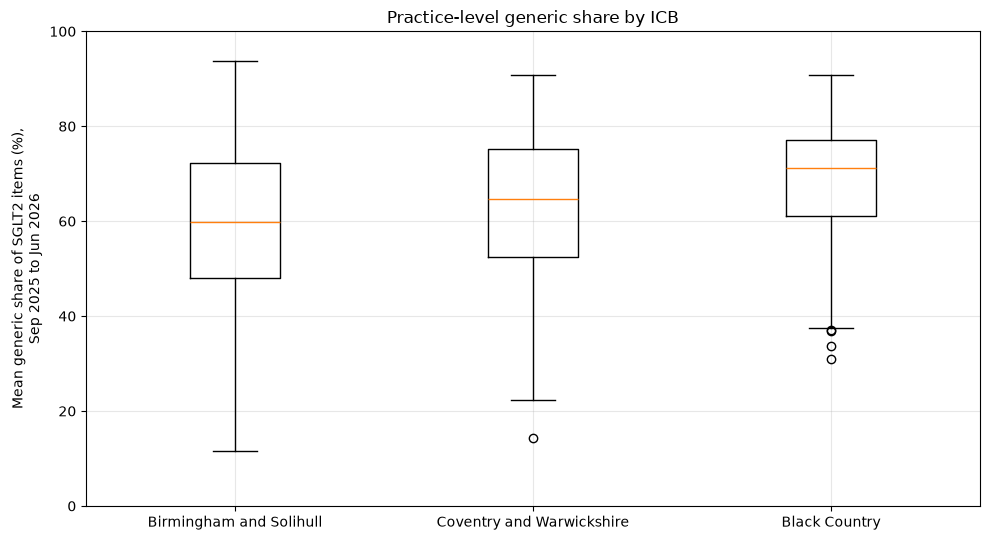

In [13]:
desc = regression_df.groupby('icb').agg(
    practices=('org_id', 'count'),
    mean_generic_share=('avg_generic_share', 'mean'),
    median_generic_share=('avg_generic_share', 'median'),
    sd_generic_share=('avg_generic_share', 'std'),
    mean_imd=('imd_practice', 'mean'),
    mean_diabetes_prev=('diabetes_prevalence', 'mean'),
    median_list_size=('list_size', 'median'))
print(desc.round(3).to_string())
print('\nDistinct districts:', regression_df['district'].nunique())

ORDER = ['Birmingham and Solihull', 'Coventry and Warwickshire', 'Black Country']   # same order as the tables
fig, ax = plt.subplots(figsize=(10, 5.5))
groups = [regression_df.loc[regression_df['icb'] == n, 'avg_generic_share'] * 100 for n in ORDER]
ax.boxplot(groups)
ax.set_xticklabels(ORDER)
ax.set_ylabel('Mean generic share of SGLT2 items (%),\nSep 2025 to Jun 2026')
ax.set_title('Practice-level generic share by ICB')
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('practice_generic_share_by_icb.png', dpi=300, bbox_inches='tight')
plt.show()

**Acknowledgement of AI assistance**

This notebook was written by Mifta Mahmood with assistance from Claude (Anthropic), a generative AI assistant, which helped to write and debug the code. All code was run, checked and verified by the author, and the outputs shown are from the author's own runs. The final decisions on data, methods and interpretation are the author's own.